# Tech Challenge Fase 2 — Classificação de Vinhos

**Pergunta de negócio:** é possível priorizar amostras com maior probabilidade de alta qualidade a partir de medições físico-químicas?

O alvo binário segue o enunciado: `quality >= 7` representa alta qualidade. A análise usa o mesmo pacote Python chamado pelo script da pipeline, evitando divergência entre notebook e resultados oficiais.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

project_root = next(
    (
        candidate
        for candidate in [Path.cwd(), *Path.cwd().parents]
        if (candidate / "data" / "raw" / "WineQT.csv").exists()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Execute o notebook a partir do projeto Tech-Challenge-Fase-2-"
        "Classificacao-de-Vinhos ou de uma pasta filha."
    )
sys.path.insert(0, str(project_root / "src"))

from wine_quality.data import (
    deduplicate_profiles,
    load_dataset,
    prepare_dataset,
    profile_duplicate_summary,
    split_dataset,
)
from wine_quality.modeling import build_models, evaluate_model, feature_importance, fit_models

data_path = project_root / "data" / "raw" / "WineQT.csv"
results_path = project_root / "results"
sns.set_theme(style="whitegrid")

## 1. Compreensão dos dados

In [2]:
raw_frame = load_dataset(data_path)
duplicate_summary = profile_duplicate_summary(raw_frame)
frame = deduplicate_profiles(raw_frame)
print(f"Linhas brutas: {len(raw_frame):,}".replace(",", "."))
print(f"Perfis únicos usados na modelagem: {len(frame):,}".replace(",", "."))
print(f"Colunas: {frame.shape[1]}")
print(f"Valores ausentes: {int(frame.isna().sum().sum())}")
print(f"Ids duplicados: {int(frame['Id'].duplicated().sum())}")
print(
    f"Perfis repetidos: {duplicate_summary['duplicate_profile_groups']} grupos; "
    f"{duplicate_summary['removed_duplicate_rows']} linhas removidas"
)
display(frame.head())

Linhas brutas: 1.143
Perfis únicos usados na modelagem: 1.018
Colunas: 13
Valores ausentes: 0
Ids duplicados: 0
Perfis repetidos: 114 grupos; 125 linhas removidas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,5


A modelagem usa uma ocorrência por combinação de medições físico-químicas e `quality`. O CSV bruto permanece preservado; a base limpa tem 1.018 perfis únicos.

In [3]:
features, target = prepare_dataset(frame, threshold=7)
summary = pd.DataFrame({
    "classe": ["Baixa/média (< 7)", "Alta (>= 7)"],
    "quantidade": [(target == 0).sum(), (target == 1).sum()],
    "participação": [(target == 0).mean(), (target == 1).mean()],
})
display(summary.style.format({"participação": "{:.1%}"}))

,classe,quantidade,participação
0,Baixa/média (< 7),881,86.5%
1,Alta (>= 7),137,13.5%


A classe positiva representa uma parcela pequena do dataset. Por isso, accuracy isolada não é suficiente: a avaliação acompanha precision, recall, F1, ROC-AUC e Average Precision.

## 2. Análise exploratória

In [4]:
display(frame[features.columns.tolist() + ["quality"]].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.289,1.741,4.600,7.100,7.900,9.100,15.900
volatile acidity,1018.0,0.534,0.183,0.120,0.390,0.520,0.645,1.580
citric acid,1018.0,0.269,0.196,0.000,0.090,0.250,0.420,1.000
residual sugar,1018.0,2.524,1.315,0.900,1.900,2.200,2.600,15.500
chlorides,1018.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1018.0,15.649,10.177,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1018.0,46.326,33.124,6.000,21.000,38.000,62.000,289.000
density,1018.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1018.0,3.312,0.158,2.740,3.210,3.310,3.400,4.010
sulphates,1018.0,0.657,0.168,0.330,0.550,0.620,0.720,2.000


In [5]:
outlier_summary = pd.read_csv(results_path / "tables" / "outlier_summary.csv")
display(outlier_summary.style.format({"outlier_share": "{:.1%}"}))

,feature,outlier_count,outlier_share,lower_fence,upper_fence
0,residual sugar,95,9.3%,0.850000,3.650000
1,chlorides,71,7.0%,0.040000,0.120000
2,sulphates,41,4.0%,0.295000,0.975000
3,fixed acidity,37,3.6%,4.100000,12.100000
4,total sulfur dioxide,33,3.2%,-40.500000,123.500000
5,density,30,2.9%,0.992190,1.001210
6,pH,24,2.4%,2.925000,3.685000
7,free sulfur dioxide,16,1.6%,-14.000000,42.000000
8,volatile acidity,10,1.0%,0.007500,1.027500
9,alcohol,6,0.6%,6.950000,13.750000


O critério IQR serve como sinalização inicial. Os valores extremos permanecem na base até que uma análise de domínio determine se são erros de medição ou observações legítimas.

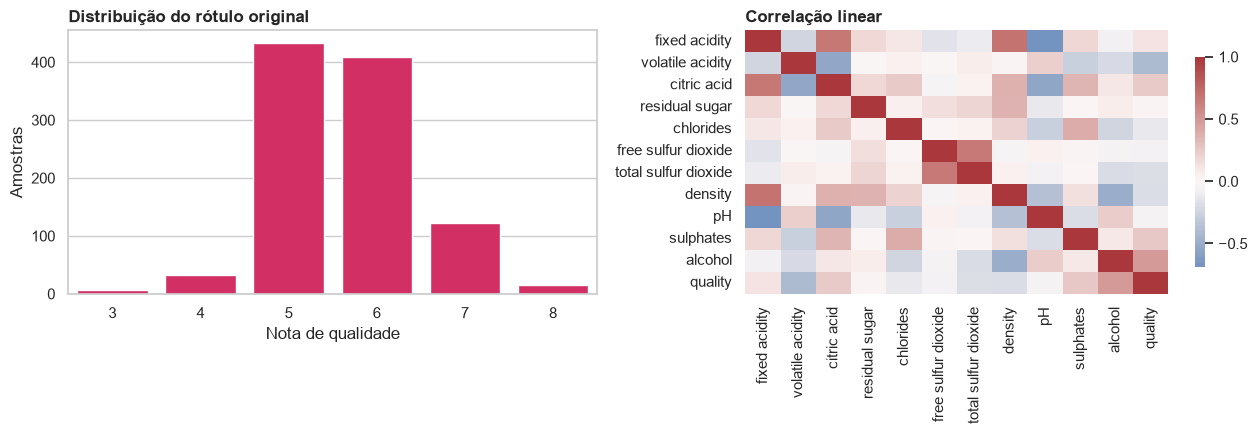

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=frame, x="quality", color="#ED145B", ax=axes[0])
axes[0].set_title("Distribuição do rótulo original", loc="left", fontweight="bold")
axes[0].set_xlabel("Nota de qualidade")
axes[0].set_ylabel("Amostras")
sns.heatmap(
    frame[features.columns.tolist() + ["quality"]].corr(),
    cmap="vlag",
    center=0,
    ax=axes[1],
    cbar_kws={"shrink": 0.8},
)
axes[1].set_title("Correlação linear", loc="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [7]:
correlation_with_quality = (
    frame[features.columns.tolist() + ["quality"]]
    .corr()["quality"]
    .drop("quality")
    .sort_values(ascending=False)
    .to_frame("correlação")
)
display(correlation_with_quality.round(3))

,correlação
alcohol,0.486
sulphates,0.258
citric acid,0.242
fixed acidity,0.116
residual sugar,0.023
pH,-0.058
free sulfur dioxide,-0.071
chlorides,-0.122
total sulfur dioxide,-0.182
density,-0.185


A associação linear mais forte aparece em `alcohol` (positiva) e `volatile acidity` (negativa). Isso orienta a investigação, mas não prova causalidade nem substitui validação fora da amostra.

## 3. Modelagem e comparação

In [8]:
X_train, X_test, y_train, y_test = split_dataset(
    features, target, test_size=0.2, random_state=42
)
models = build_models(random_state=42)
fitted_models = fit_models(models, X_train, y_train)
metrics = pd.DataFrame(
    {
        name: evaluate_model(model, X_test, y_test)
        for name, model in fitted_models.items()
    }
).T
display(metrics.round(3))

,accuracy,precision,recall,f1,roc_auc,average_precision
logistic_regression,0.784,0.356,0.778,0.488,0.882,0.441
random_forest,0.902,0.733,0.407,0.524,0.925,0.692


In [9]:
comparison = pd.read_csv(results_path / "tables" / "model_comparison.csv")
display(comparison.style.format({column: "{:.3f}" for column in comparison.columns if column != "model"}))

,model,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_average_precision,cv_mean_accuracy,cv_mean_precision,cv_mean_recall,cv_mean_f1,cv_mean_roc_auc,cv_mean_average_precision,cv_std_accuracy,cv_std_precision,cv_std_recall,cv_std_f1,cv_std_roc_auc,cv_std_average_precision
0,logistic_regression,0.784,0.356,0.778,0.488,0.882,0.441,0.792,0.378,0.827,0.519,0.872,0.546,0.018,0.025,0.067,0.031,0.033,0.109
1,random_forest,0.902,0.733,0.407,0.524,0.925,0.692,0.877,0.585,0.373,0.448,0.874,0.570,0.029,0.162,0.116,0.123,0.040,0.150


In [10]:
importance = pd.concat(
    [
        feature_importance(model, list(features.columns)).assign(model=name)
        for name, model in fitted_models.items()
    ],
    ignore_index=True,
)
display(importance.groupby("model").head(5))

,feature,importance,direction,signed_value,model
0,alcohol,0.860750,positive,0.860750,logistic_regression
1,sulphates,0.714544,positive,0.714544,logistic_regression
2,density,0.712780,negative,-0.712780,logistic_regression
3,fixed acidity,0.609514,positive,0.609514,logistic_regression
4,volatile acidity,0.578920,negative,-0.578920,logistic_regression
11,alcohol,0.216702,positive,0.216702,random_forest
12,volatile acidity,0.134705,positive,0.134705,random_forest
13,sulphates,0.131488,positive,0.131488,random_forest
14,citric acid,0.098556,positive,0.098556,random_forest
15,density,0.085860,positive,0.085860,random_forest


## 4. Conclusões executivas

In [11]:
best_model = metrics["average_precision"].idxmax()
print(
    f"O melhor desempenho no conjunto de teste foi do {best_model}, "
    f"com Average Precision de {metrics.loc[best_model, 'average_precision']:.3f}."
)
print(
    "Recomendação: usar o classificador como triagem de amostras e apoio ao enólogo, "
    "com calibração de limiar e validação sensorial antes de automatizar decisões."
)

O melhor desempenho no conjunto de teste foi do random_forest, com Average Precision de 0.692.
Recomendação: usar o classificador como triagem de amostras e apoio ao enólogo, com calibração de limiar e validação sensorial antes de automatizar decisões.


### Limitações

- O rótulo de qualidade é uma avaliação especializada e pode conter subjetividade.
- A classe positiva é pequena, o que aumenta a incerteza das métricas.
- O dataset não contém custos, lote, região, processo de produção ou medidas sensoriais detalhadas.
- Correlação e importância de variável indicam associação preditiva, não causalidade.